# Análisis Exploratorio de Datos - Primer acercamiento

En este notebook vamos a tratar de entender los principales patrones que siguen los datos con los que vamos a trabajar. De primeras sabemos que el dataset es un histórico de reserva de hoteles y que el problema consistirá en clasificar si la reserva será cancelada o no.

## Hipótesis iniciales
Para que nuestro análisis siga una dirección concreta, vamos a plantear una serie de hipótesis sobre el comportamiento de los clientes, las características de la reserva y las condiciones del hotel.

**Antelación de la reserva**
- Cuanto mayor sea la antelación con la que se hizo la reserva, mayor será la probabilidad de cancelación.
- En cambio las de menor cancelación tienen menor probabilidad, ya que podrían responder a necesidades de alojamiento inmediatas.
- La relación entre antelación y tasa de cancelación no es lineal: podría existir un umbral de antelación que dispare la probabilidad de cancelación.

**Características del cliente**
- Los clientes que ya realizaron reservas en otras ocasiones son menos propensos a cancelar.
- Los clientes que ya cancelaron en otras ocasiones son más probables a volver a cancelar.

**Características económicas**
- Las reservas de mayor coste tienen mayor probabilidad de cancelación.
- Las reservas que requieren un depósito no reembolsable presentan una menor tasa de cancelación. En cambio, las de depósito reembolsable o sin depósito presentan una mayor probabilidad de cancelación.

**Canal de distribución**
- Las reservas realizadas mediante agencias de viajes (TA/TO) presentan una tasa de cancelación diferente a las realizadas directamente con el hotel.
- Las reservas online tienen mayor probabilidad de cancelación que las realizadas por otros canales.
- Los clientes que vienen por parte de empresas tienen menor probabilidad de cancelar.

**Características temporales**
- Las reservas correspondientes a temporadas de alta demanda presentan una menor tasa de cancelación.
- La tasa de cancelación varía dependiendo del mes de llegada.
- Las reservas realizadas para fines de semana presentan un comportamiento de cancelación diferente a las reservas entre semana.

**Características de la estancia**
- Las reservas con mayor duración tienen una mayor probabilidad de cancelación.
- Las reservas realizadas para grupos o familias presentan un comportamiento de cancelación diferente al de las reservas individuales.
- Las reservas que incluyen solicitudes especiales presentan una menor probabilidad de cancelación, debido a que son clientes más comprometidos con la estancia.

In [2]:
# Importamos librerías necesarias
from pathlib import Path
import pandas as pd

ROOT_PATH = Path("../..")
DATA_PATH = ROOT_PATH / "data" / "raw" / "dataset_practica_final.csv"

# Cargamos el dataset
reservas_df = pd.read_csv(DATA_PATH)

reservas_df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
# Imprimimos información general del DataFrame
print("___"*10, "INFORMACIÓN", "___"*10)
print(reservas_df.info())
print("==="*24)



______________________________ INFORMACIÓN ______________________________
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies         

## Tipos de características
Vamos a empezar por agrupar las variables según su naturaleza (categóricas, numéricas, booleanas).

### Categóricas nominales

Estas variables representan grupos o etiquetas sin jerarquía.

| Variable | Descripción |
|---|---|
| `hotel` | Tipo de hotel |
| `arrival_date_month` | Mes de llegada |
| `meal` | Tipo de régimen alimenticio |
| `country` | País de procedencia |
| `market_segment` | Segmento de mercado |
| `distribution_channel` | Canal de distribución |
| `reserved_room_type` | Tipo de habitación reservada |
| `assigned_room_type` | Tipo de habitación asignada |
| `deposit_type` | Tipo de depósito |
| `agent` | Identificador de la agencia |
| `company` | Identificador de la empresa |
| `reservation_status` | Estado final de la reserva |
| `reservation_status_date` | Fecha del último cambio de estado |

**Observaciones:**

- `agent` y `company` son identificadores.
- `arrival_date_month` tiene una naturaleza temporal (meses del año), pero la vamos a considerar nominal sin jerarquía por simplicidad.
- `reservation_status_date` debería convertirse a `datetime` para trabajar con ella como variable temporal. De aquí podrían salir nuevas características.

In [4]:
# Categóricas nominales
categorical_nominal = [
    "hotel",
    "arrival_date_month",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "assigned_room_type",
    "deposit_type",
    "agent",
    "company",
    "reservation_status",
    "reservation_status_date"
]

### Categóricas ordinales (jerárquicas)

Podrían tratarse como nominales también, pero podemos asignarles la siguiente jerarquía.

| Variable | Posible orden | Observaciones |
|---|---|---|
| `customer_type` | Contract, Group, Transient, Transient-Party | No existe un orden jerárquico universal. |
| `deposit_type` | No Deposit, Refundable, Non Refund | El orden depende de cómo definamos la dimensión de comparación. |

In [5]:
# Categóricas ordinales
categorical_ordinal = [
    "customer_type",
    "deposit_type"
]

### Numéricas discretas

Estas características representan cantidades enteras. No son valores continuos.

| Variable | Descripción |
|---|---|
| `lead_time` | Días entre reserva y llegada |
| `arrival_date_year` | Año de llegada |
| `arrival_date_week_number` | Semana del año |
| `arrival_date_day_of_month` | Día del mes |
| `stays_in_weekend_nights` | Noches durante el fin de semana |
| `stays_in_week_nights` | Noches entre semana |
| `adults` | Número de adultos |
| `children` | Número de niños |
| `babies` | Número de bebés |
| `previous_cancellations` | Cancelaciones anteriores |
| `previous_bookings_not_canceled` | Reservas anteriores no canceladas |
| `booking_changes` | Cambios realizados en la reserva |
| `days_in_waiting_list` | Días en lista de espera |
| `required_car_parking_spaces` | Plazas de aparcamiento solicitadas |
| `total_of_special_requests` | Número de solicitudes especiales |

In [6]:
# Numéricas discretas
numerical_discrete = [
    "lead_time",
    "arrival_date_year",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "days_in_waiting_list",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

### Numéricas continuas

Son variables que representan magnitudes y pueden tomar valores decimales.

| Variable | Descripción |
|---|---|
| `adr` | Average Daily Rate: precio medio diario de la reserva |

Para este tipo de variable hay que prestar atención a posibles valores atípicos o ruidosos.

In [7]:
# Numéricas continuas
numerical_continuous = [
    "adr"
]

### Booleanas

Representan dos posibles estados.

| Variable | Valores | Significado |
|---|---|---|
| `is_canceled` | 0 / 1 | Reserva no cancelada / cancelada |
| `is_repeated_guest` | 0 / 1 | Cliente nuevo / cliente recurrente |

Según la naturaleza del algoritmo de Machine Learning, se tendrán que codificar como `boolean` o `int`.

In [8]:
# Booleanas
boolean_variables = [
    "is_canceled",
    "is_repeated_guest"
]

## Antelación de reserva

Recordemos nuestras hipótesis:

- Cuanto mayor sea la antelación con la que se hizo la reserva, mayor será la probabilidad de cancelación.
- En cambio las de menor cancelación tienen menor probabilidad, ya que podrían responder a necesidades de alojamiento inmediatas.
- La relación entre antelación y tasa de cancelación no es lineal: podría existir un umbral de antelación que dispare la probabilidad de cancelación.

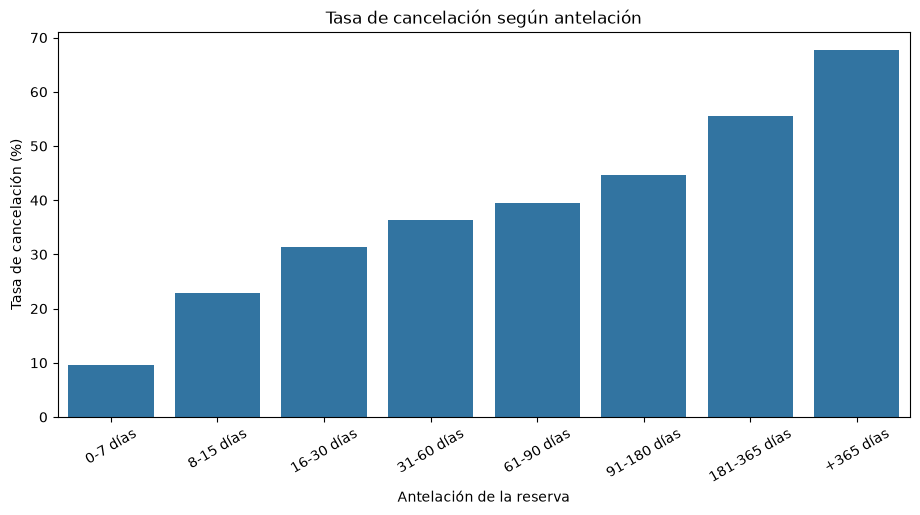

In [9]:

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

bins = [0, 7, 15, 30, 60, 90, 180, 365, np.inf]

labels = [
    "0-7 días",
    "8-15 días",
    "16-30 días",
    "31-60 días",
    "61-90 días",
    "91-180 días",
    "181-365 días",
    "+365 días"
]

reservas_df["lead_time_group"] = pd.cut(
    reservas_df["lead_time"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

cancellation_rate = (
    reservas_df.groupby("lead_time_group", observed=False)["is_canceled"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=cancellation_rate.index,
    y=cancellation_rate.values
)

plt.title("Tasa de cancelación según antelación")
plt.xlabel("Antelación de la reserva")
plt.ylabel("Tasa de cancelación (%)")
plt.xticks(rotation=30)
plt.show()


Nuestra primera hipótesis cobra sentido. Conforme aumenta el número de días de antelación la tasa de cancelación también lo hace. Veamos si esta relación es lineal.

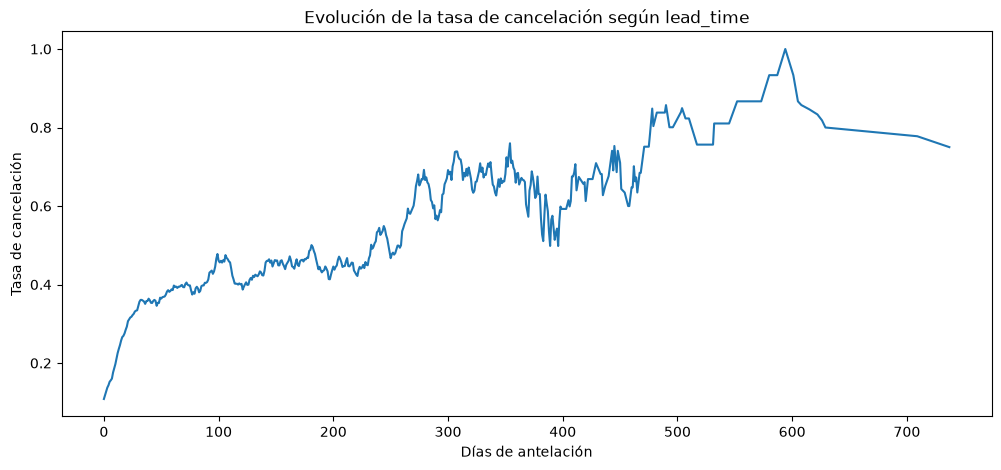

In [10]:

lead_time_rate = (
    reservas_df.groupby("lead_time")["is_canceled"]
    .agg(["mean", "count"])
    .reset_index()
)

# Media móvil de 15 días de antelación
lead_time_rate["rolling_rate"] = (
    lead_time_rate["mean"]
    .rolling(window=15, center=True, min_periods=5)
    .mean()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=lead_time_rate,
    x="lead_time",
    y="rolling_rate"
)

plt.title("Evolución de la tasa de cancelación según lead_time")
plt.xlabel("Días de antelación")
plt.ylabel("Tasa de cancelación")
plt.show()


En efecto, hasta los primeros 50 días la tasa de cancelación aumenta de forma más rápida cada día. A partir de ahí, el aumento de la tasa de cancelación sigue en aumento pero no con la misma tendencia. A diferencia de lo que supusimos, no existe un umbral que dispare la tasa de cancelación, si no que su crecimiento atenua con el incremento de los días de antelación.

## Características del cliente

Nuestras hipótesis:
- Los clientes que ya realizaron reservas en otras ocasiones son menos propensos a cancelar.
- Los clientes que ya cancelaron en otras ocasiones son más probables a volver a cancelar.

In [11]:

# Calculamos el número de reservas y la tasa de cancelación
repeated_guest_analysis = (
    reservas_df.groupby("is_repeated_guest")
    .agg(
        total_reservas=("is_canceled", "count"),
        cancelaciones=("is_canceled", "sum"),
        tasa_cancelacion=("is_canceled", "mean")
    )
)

repeated_guest_analysis["tasa_cancelacion"] *= 100

display(repeated_guest_analysis.round(2))


,total_reservas,cancelaciones,tasa_cancelacion
is_repeated_guest,,,
0,115580,43672,37.79
1,3810,552,14.49


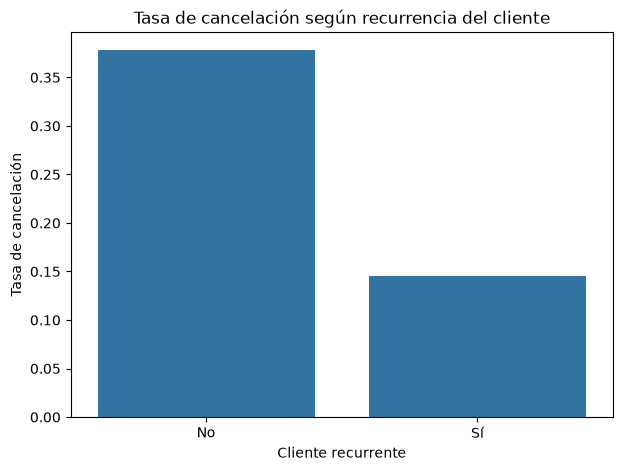

In [12]:

plt.figure(figsize=(7, 5))

sns.barplot(
    data=reservas_df,
    x="is_repeated_guest",
    y="is_canceled",
    errorbar=None
)

plt.title("Tasa de cancelación según recurrencia del cliente")
plt.xlabel("Cliente recurrente")
plt.ylabel("Tasa de cancelación")
plt.xticks([0, 1], ["No", "Sí"])
plt.show()


En primer lugar, contamos con muchas más muestras de reservas no repetidas que repetidas, así que hemos calculado el cociente entre cancelaciones y toal de reservas. Como resultado tenemos que la tasa de cancelación en usuarios nuevos es **mayor de 20 puntos porcentauales** que en las reservas de usuarios que repitieron.

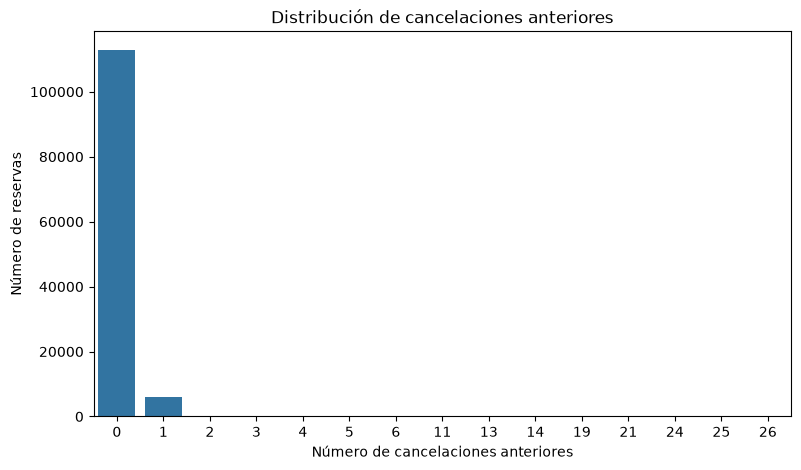

In [13]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=reservas_df,
    x="previous_cancellations"
)

plt.title("Distribución de cancelaciones anteriores")
plt.xlabel("Número de cancelaciones anteriores")
plt.ylabel("Número de reservas")
plt.show()


La inmensa mayoría de reservas las hacen usuarios que no cancelaron anteriormente. Una minoría lo hizo alguna vez.

In [14]:

previous_cancellations_analysis = (
    reservas_df.groupby("previous_cancellations")
    .agg(
        total_reservas=("is_canceled", "count"),
        cancelaciones=("is_canceled", "sum"),
        tasa_cancelacion=("is_canceled", "mean")
    )
)

previous_cancellations_analysis["tasa_cancelacion"] *= 100

display(previous_cancellations_analysis.round(2))


,total_reservas,cancelaciones,tasa_cancelacion
previous_cancellations,,,
0,112906,38282,33.91
1,6051,5714,94.43
2,116,38,32.76
3,65,20,30.77
4,31,7,22.58
5,19,2,10.53
6,22,7,31.82
11,35,10,28.57
13,12,11,91.67


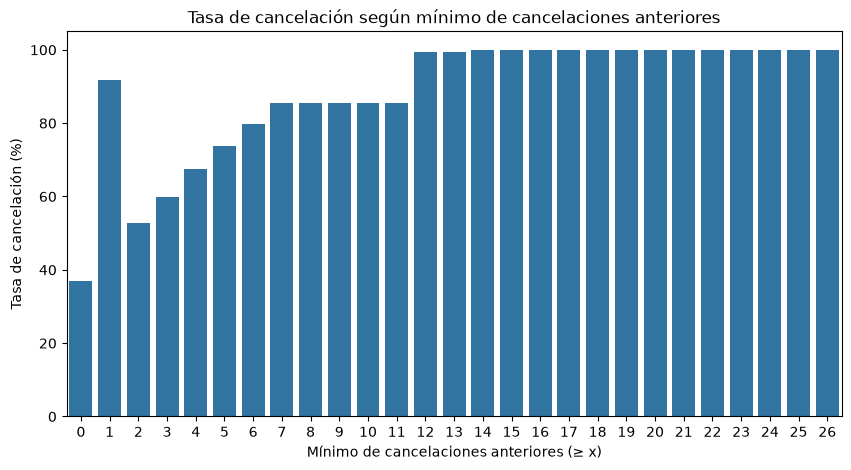

In [15]:

# Calculamos la tasa de cancelación para cada umbral
max_cancellations = reservas_df["previous_cancellations"].max()

threshold_analysis = []

for x in range(max_cancellations + 1):
    subset = reservas_df[
        reservas_df["previous_cancellations"] >= x
    ]

    threshold_analysis.append({
        "min_previous_cancellations": x,
        "total_reservas": len(subset),
        "tasa_cancelacion": subset["is_canceled"].mean() * 100
    })

threshold_df = pd.DataFrame(threshold_analysis)

# Visualización
plt.figure(figsize=(10, 5))

sns.barplot(
    data=threshold_df,
    x="min_previous_cancellations",
    y="tasa_cancelacion",
    errorbar=None
)

plt.title("Tasa de cancelación según mínimo de cancelaciones anteriores")
plt.xlabel("Mínimo de cancelaciones anteriores (≥ x)")
plt.ylabel("Tasa de cancelación (%)")
plt.show()


Podemos confirmar que el número de cancelaciones anteriores puede ser un indicador muy correlacionado con la tasa de cancelación.

## Características económicas

Recordemos nuestras hipótesis:

- Las reservas de mayor coste tienen mayor probabilidad de cancelación.
- Las reservas que requieren un depósito no reembolsable presentan una menor tasa de cancelación. En cambio, las de depósito reembolsable o sin depósito presentan una mayor probabilidad de cancelación.

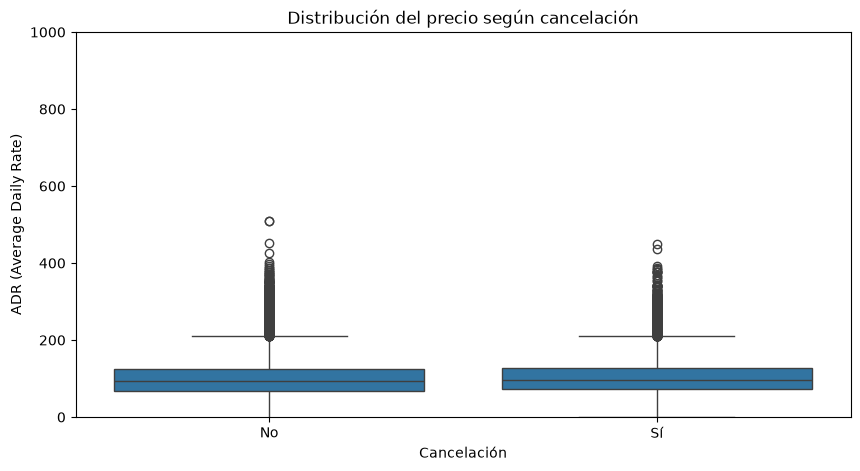

In [16]:
# Graficamos la distribución del precio medio diario de la reserva por clase
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=reservas_df,
    x="is_canceled",
    y="adr"
)

plt.title("Distribución del precio según cancelación")
plt.xlabel("Cancelación")
plt.ylabel("ADR (Average Daily Rate)")
plt.xticks([0, 1], ["No", "Sí"])
plt.ylim(0, 1000)
plt.show()


La distribución estadística es muy similar entre ambas clases. No discrimina muy bien si hubo cancelación o no.

,total_reservas,cancelaciones,tasa_cancelacion
adr_group,,,
"(-6.381, 64.0]",23912,8361,34.97
"(64.0, 85.0]",24476,8375,34.22
"(85.0, 105.0]",23278,9151,39.31
"(105.0, 135.0]",24390,9552,39.16
"(135.0, 5400.0]",23334,8785,37.65


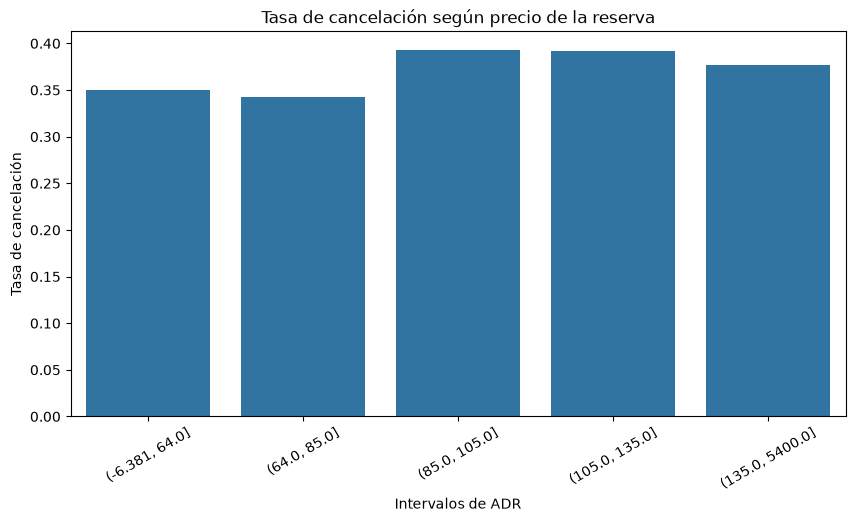

In [ ]:
# Dividimos las reservas en cinco grupos según ADR
reservas_df["adr_group"] = pd.qcut(
    reservas_df["adr"],
    q=5,
    duplicates="drop"
)

# Calculamos estadísticas por grupo
adr_analysis = (
    reservas_df.groupby("adr_group", observed=True)
    .agg(
        total_reservas=("is_canceled", "count"),
        cancelaciones=("is_canceled", "sum"),
        tasa_cancelacion=("is_canceled", "mean")
    )
)

adr_analysis["tasa_cancelacion"] *= 100

display(adr_analysis.round(2))

# Visualización
plt.figure(figsize=(10, 5))

sns.barplot(
    data=reservas_df,
    x="adr_group",
    y="is_canceled",
    errorbar=None
)

plt.title("Tasa de cancelación según precio de la reserva")
plt.xlabel("Intervalos de ADR")
plt.ylabel("Tasa de cancelación")
plt.xticks(rotation=30)
plt.show()


Por otro lado, el precio de la estancia no repercute en la tasa de cancelación de forma considerable.

In [26]:
reservas_df.iloc[reservas_df.deposit_type == "Non Refund"].groupby("is_canceled").count()

,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,lead_time_group,adr_group
is_canceled,,,,,,,,,,,,,,,,,,,,,
0,93,93,93,93,93,93,93,93,93,93,...,33,93,93,93,93,93,93,93,93,93
1,14494,14494,14494,14494,14494,14494,14494,14494,14494,14494,...,473,14494,14494,14494,14494,14494,14494,14494,14494,14494


In [ ]:
# Calculamos estadísticas por tipo de depósito
deposit_analysis = (
    reservas_df.groupby("deposit_type")
    .agg(
        total_reservas=("is_canceled", "count"),
        cancelaciones=("is_canceled", "sum"),
        tasa_cancelacion=("is_canceled", "mean")
    )
)

deposit_analysis["tasa_cancelacion"] *= 100

display(deposit_analysis.round(2))


,total_reservas,cancelaciones,tasa_cancelacion
deposit_type,,,
No Deposit,104641,29694,28.38
Non Refund,14587,14494,99.36
Refundable,162,36,22.22


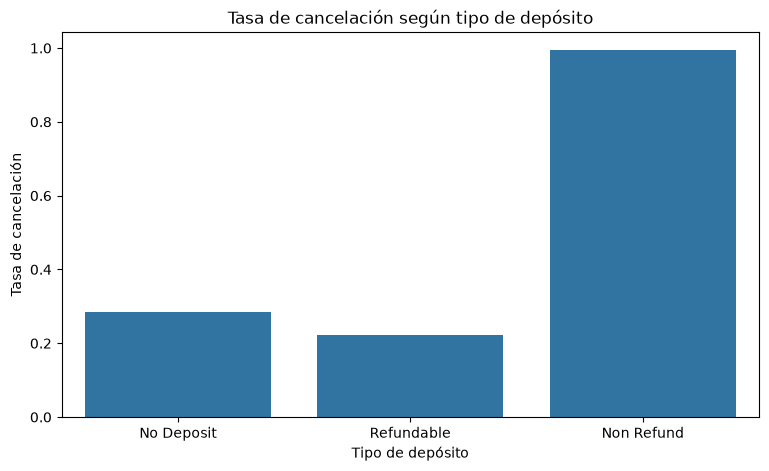

In [28]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=reservas_df,
    x="deposit_type",
    y="is_canceled",
    order=["No Deposit", "Refundable", "Non Refund"],
    errorbar=None
)

plt.title("Tasa de cancelación según tipo de depósito")
plt.xlabel("Tipo de depósito")
plt.ylabel("Tasa de cancelación")
plt.show()


Los resultados de comparar `deposit_type` con la tasa de retención son muy llamativos. Sería de esperar que aquellas reservas no reembolsables tengan menor tasa de cancelación y sin embargo, ¡es casi del 100%! 

**Prestemos especial atención aquí**. Muchos registros etiquetados como *Non Refund* no son turistas reservando por su cuenta, sino agencias de viajes y turoperadores que bloquean grandes cupos de habitaciones con mucha antelación (`lead_time` muy alto). Estas entidades pagan un depósito no reembolsable para asegurar disponibilidad y tarifas bajas, y meses antes de la fecha cancelan las habitaciones que no lograron vender (asumiendo la pérdida como parte de su modelo de negocio o negociando compensaciones con el hotel). Veamos cómo se comporta la distribución de medias de muestras bootstrap sobre el `lead_time` en reservas no reembolsables canceladas y no canceladas.

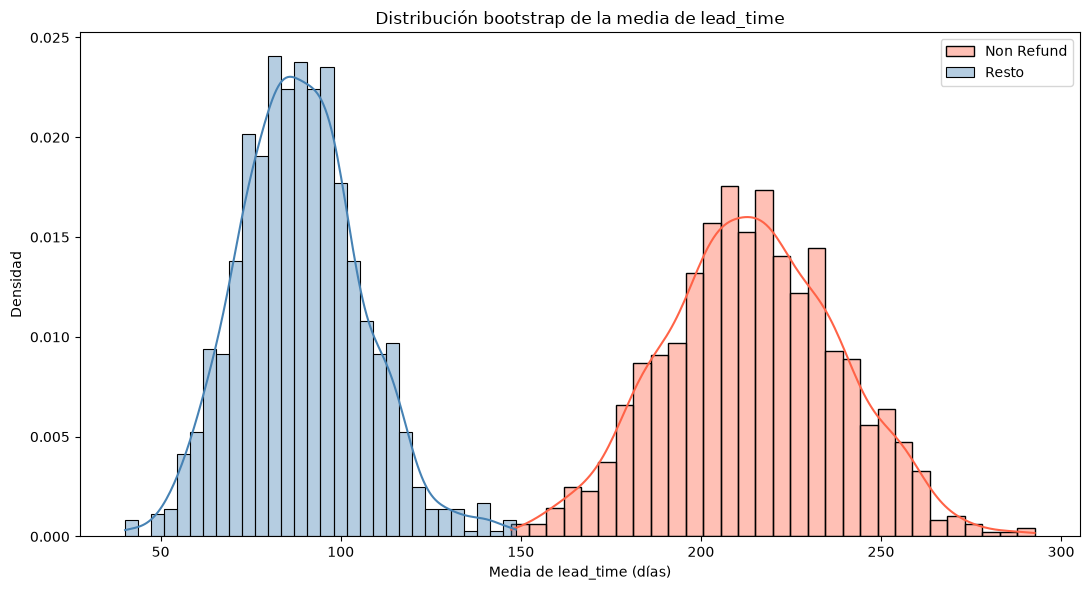

In [60]:

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Separar los dos grupos
non_refund = reservas_df.loc[
    reservas_df["deposit_type"] == "Non Refund",
    "lead_time"
].dropna().to_numpy()

resto = reservas_df.loc[
    reservas_df["deposit_type"] != "Non Refund",
    "lead_time"
].dropna().to_numpy()


def bootstrap_means(data, sample_size=30, n_iterations=1000):
    means = []

    for _ in range(n_iterations):
        sample = np.random.choice(
            data,
            size=sample_size,
            replace=True
        )

        means.append(sample.mean())

    return np.array(means)


# Simulación Monte Carlo + Bootstrap
np.random.seed(42)

means_non_refund = bootstrap_means(non_refund)
means_resto = bootstrap_means(resto)


# Representar distribuciones de las medias
plt.figure(figsize=(11, 6))

sns.histplot(
    means_non_refund,
    bins=30,
    stat="density",
    kde=True,
    color="tomato",
    label="Non Refund",
    alpha=0.4
)

sns.histplot(
    means_resto,
    bins=30,
    stat="density",
    kde=True,
    color="steelblue",
    label="Resto",
    alpha=0.4
)

plt.title("Distribución bootstrap de la media de lead_time")
plt.xlabel("Media de lead_time (días)")
plt.ylabel("Densidad")
plt.legend()
plt.tight_layout()
plt.show()


Observemos también quién realiza las reservas no reembolsables.

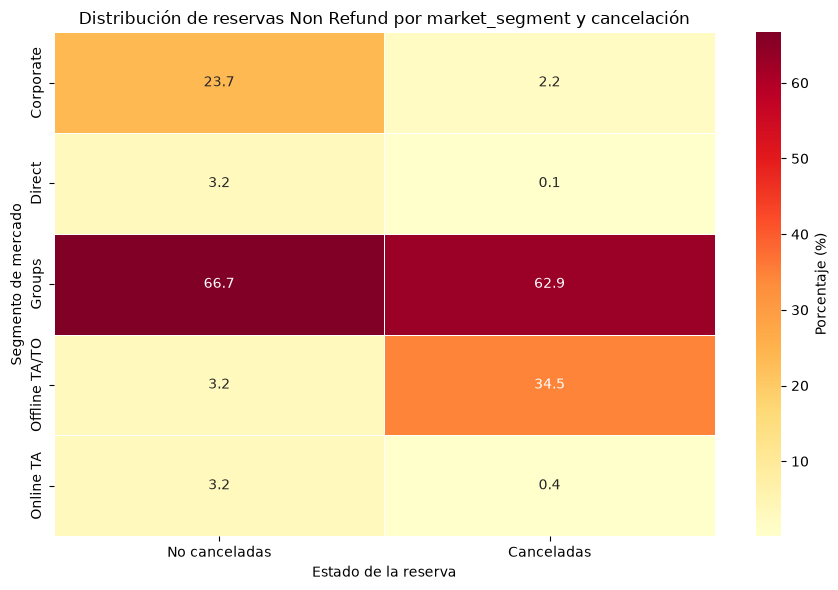

In [61]:

# Filtrar reservas Non Refund
non_refund_df = reservas_df[
    reservas_df["deposit_type"] == "Non Refund"
].copy()

# Tabla de contingencia normalizada por columnas
market_distribution = pd.crosstab(
    non_refund_df["market_segment"],
    non_refund_df["is_canceled"],
    normalize="columns"
) * 100

# Renombrar columnas
market_distribution.columns = [
    "No canceladas",
    "Canceladas"
]

# Corrplot / mapa de calor
plt.figure(figsize=(9, 6))

sns.heatmap(
    market_distribution,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Porcentaje (%)"}
)

plt.title(
    "Distribución de reservas Non Refund por market_segment y cancelación"
)
plt.xlabel("Estado de la reserva")
plt.ylabel("Segmento de mercado")

plt.tight_layout()
plt.show()


Las TA/TO apenas aparecen en las reservas no canceladas de este tipo, pero sí se hacen presentes en las canceladas. Nuestra decisión será no descartar la variable `deposit_type` que parece discriminar muy bien.

## Canal de distribución
- Las reservas realizadas mediante agencias de viajes (TA/TO) presentan una tasa de cancelación diferente a las realizadas directamente con el hotel.
- Las reservas online tienen mayor probabilidad de cancelación que las realizadas por otros canales.
- Los clientes que vienen por parte de empresas tienen menor probabilidad de cancelar.

In [62]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Filtrar los dos canales que queremos comparar
channels_df = reservas_df[
    reservas_df["distribution_channel"].isin(["TA/TO", "Direct"])
].copy()

# Calcular métricas
channel_analysis = (
    channels_df.groupby("distribution_channel")
    .agg(
        total_reservas=("is_canceled", "count"),
        cancelaciones=("is_canceled", "sum"),
        tasa_cancelacion=("is_canceled", "mean")
    )
    .reset_index()
)

channel_analysis["tasa_cancelacion"] *= 100

display(channel_analysis)


,distribution_channel,total_reservas,cancelaciones,tasa_cancelacion
0,Direct,14645,2557,17.459884
1,TA/TO,97870,40152,41.025851


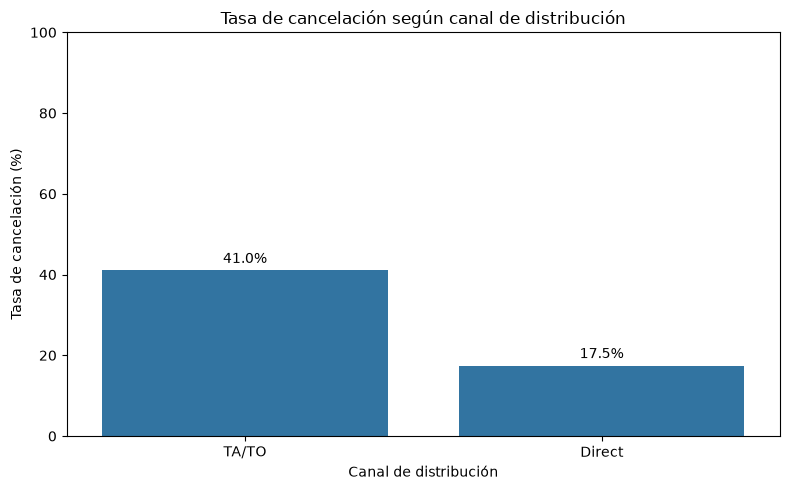

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=channel_analysis,
    x="distribution_channel",
    y="tasa_cancelacion",
    order=["TA/TO", "Direct"],
    errorbar=None
)

ax.set_title("Tasa de cancelación según canal de distribución")
ax.set_xlabel("Canal de distribución")
ax.set_ylabel("Tasa de cancelación (%)")
ax.set_ylim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


Como ya preveíamos, la tasa de cancelación es significativamente mayor en TA/TO (razón explicada anteriormente).

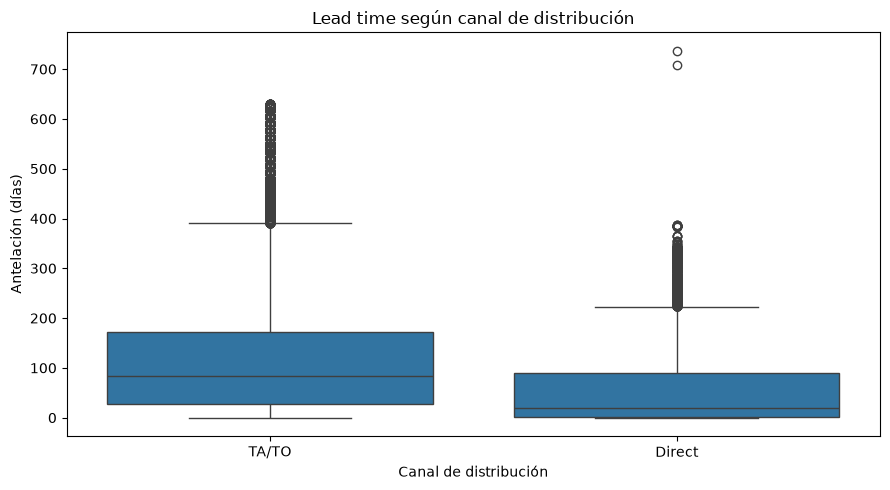

In [65]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=channels_df,
    x="distribution_channel",
    y="lead_time",
    order=["TA/TO", "Direct"]
)

plt.title("Lead time según canal de distribución")
plt.xlabel("Canal de distribución")
plt.ylabel("Antelación (días)")
plt.tight_layout()
plt.show()


Las reservas de TA/TO también tienen mayor antelacaión.

In [66]:
online_df = reservas_df.copy()

online_df["tipo_reserva"] = np.where(
    online_df["market_segment"] == "Online TA",
    "Online TA",
    "Otros segmentos"
)

online_analysis = (
    online_df.groupby("tipo_reserva")
    .agg(
        total_reservas=("is_canceled", "count"),
        cancelaciones=("is_canceled", "sum"),
        tasa_cancelacion=("is_canceled", "mean")
    )
    .reset_index()
)

online_analysis["tasa_cancelacion"] *= 100

online_analysis

,tipo_reserva,total_reservas,cancelaciones,tasa_cancelacion
0,Online TA,56477,20739,36.721143
1,Otros segmentos,62913,23485,37.329328


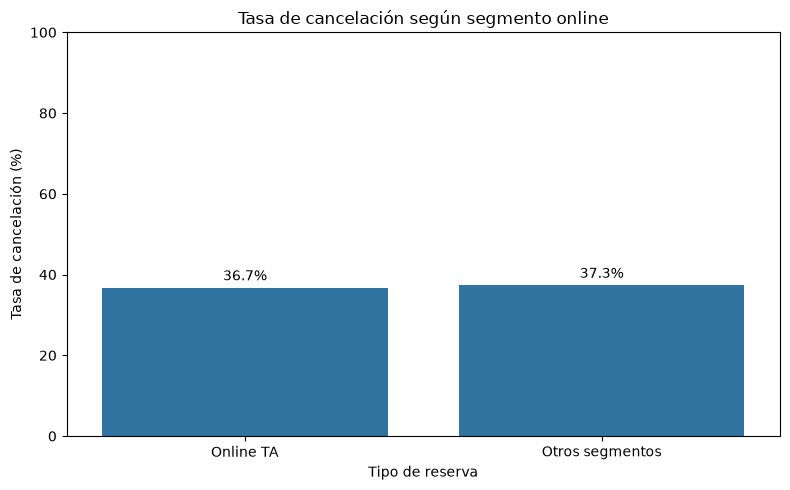

In [67]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=online_analysis,
    x="tipo_reserva",
    y="tasa_cancelacion"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Tasa de cancelación según segmento online")
plt.xlabel("Tipo de reserva")
plt.ylabel("Tasa de cancelación (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

Rechazamos la hipótesis de que las reservas realizadas online tiene una tasa de cancelación mayor que el resto. Por último, veamos si escierto que los que reservan a través de empresas tienen menor probabilidad de cancelación.

In [72]:
corporate_df = reservas_df.copy()

corporate_df["tipo_cliente"] = np.where(
    corporate_df["market_segment"] == "Corporate",
    "Corporate",
    "Otros segmentos"
)

corporate_analysis = (
    corporate_df.groupby("tipo_cliente")
    .agg(
        total_reservas=("is_canceled", "count"),
        cancelaciones=("is_canceled", "sum"),
        tasa_cancelacion=("is_canceled", "mean")
    )
    .reset_index()
)

corporate_analysis["tasa_cancelacion"] *= 100

corporate_analysis

,tipo_cliente,total_reservas,cancelaciones,tasa_cancelacion
0,Corporate,5295,992,18.734655
1,Otros segmentos,114095,43232,37.891231


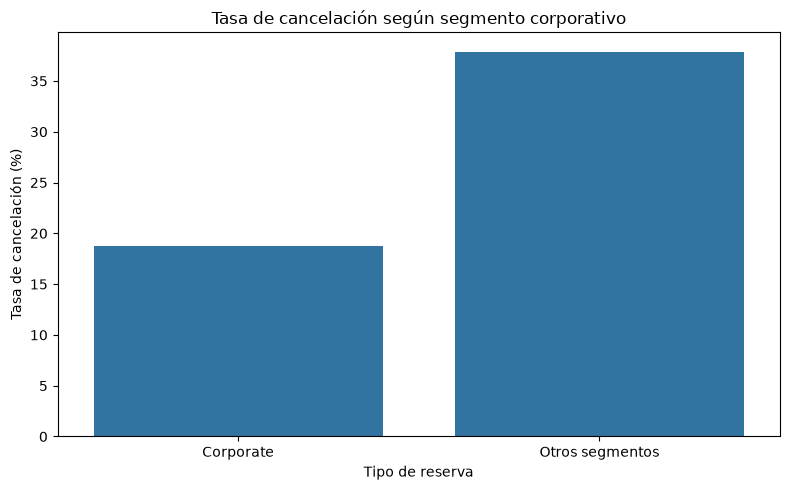

In [73]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=corporate_analysis,
    x="tipo_cliente",
    y="tasa_cancelacion"
)

plt.title("Tasa de cancelación según segmento corporativo")
plt.xlabel("Tipo de reserva")
plt.ylabel("Tasa de cancelación (%)")

plt.tight_layout()
plt.show()

Los datos muestran que esta suposición sí se cumplen.

## Características temporales

Supusimos que:
- Las reservas correspondientes a temporadas de alta demanda presentan una menor tasa de cancelación.
- La tasa de cancelación varía dependiendo del mes de llegada.
- Las reservas realizadas para fines de semana presentan un comportamiento de cancelación diferente a las reservas entre semana.


In [74]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_analysis = (
    reservas_df.groupby("arrival_date_month")
    .agg(
        total_reservas=("is_canceled", "count"),
        cancelaciones=("is_canceled", "sum"),
        tasa_cancelacion=("is_canceled", "mean")
    )
    .reindex(month_order)
    .reset_index()
)

monthly_analysis["tasa_cancelacion"] *= 100

monthly_analysis

,arrival_date_month,total_reservas,cancelaciones,tasa_cancelacion
0,January,5929,1807,30.477315
1,February,8068,2696,33.415964
2,March,9794,3149,32.152338
3,April,11089,4524,40.797186
4,May,11791,4677,39.665847
5,June,10939,4535,41.457172
6,July,12661,4742,37.453598
7,August,13877,5239,37.753117
8,September,10508,4116,39.170156
9,October,11160,4246,38.046595


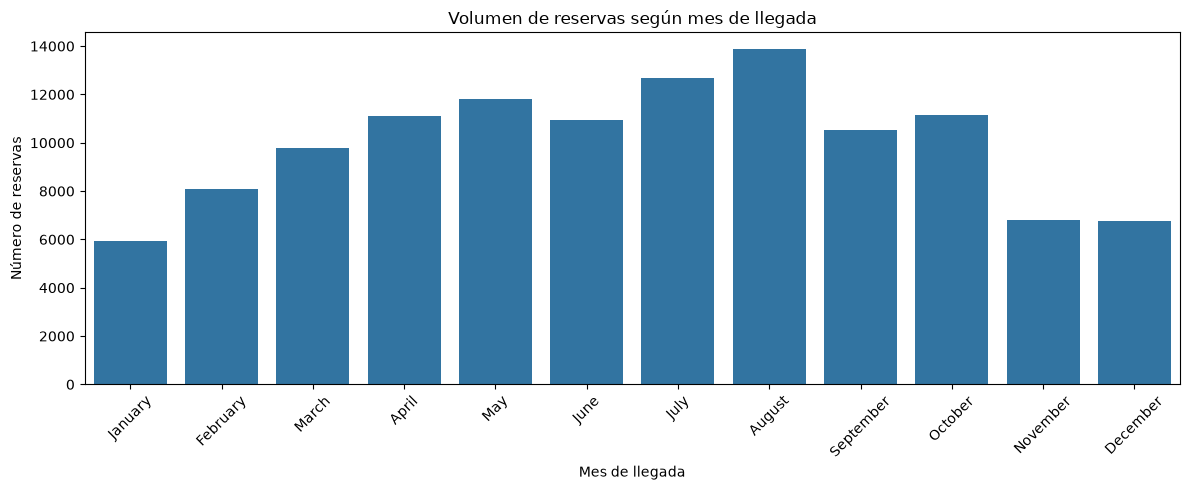

In [75]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_analysis,
    x="arrival_date_month",
    y="total_reservas"
)

plt.title("Volumen de reservas según mes de llegada")
plt.xlabel("Mes de llegada")
plt.ylabel("Número de reservas")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

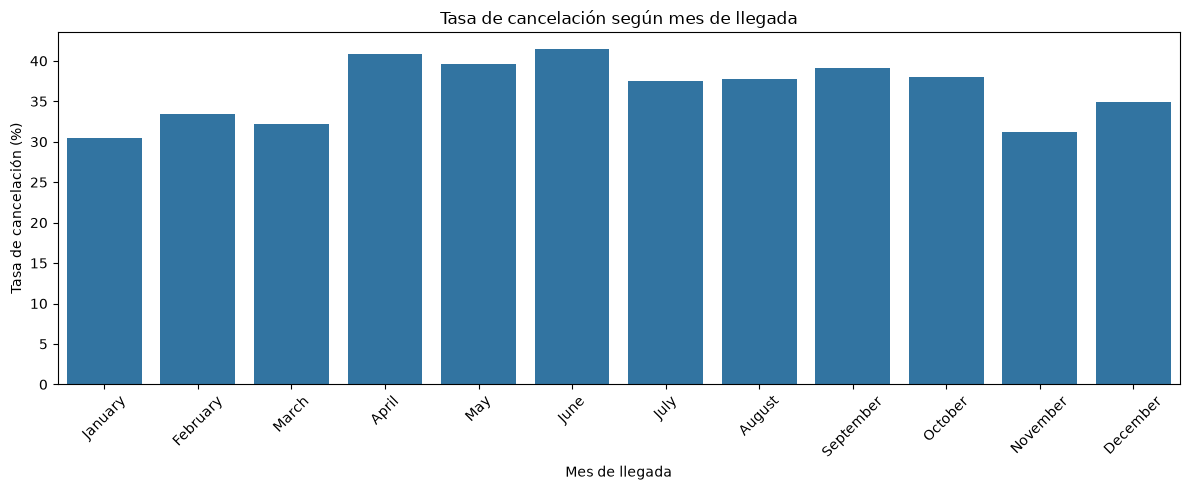

In [76]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_analysis,
    x="arrival_date_month",
    y="tasa_cancelacion"
)

plt.title("Tasa de cancelación según mes de llegada")
plt.xlabel("Mes de llegada")
plt.ylabel("Tasa de cancelación (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

La tasa de cancelación parece seguir una distribución uniforme entre todos los meses del año (en temporada alta no se aprecian diferencias). Veamos si algo cambia los fines de semana.

In [77]:
reservas_df["tipo_estancia"] = np.where(
    reservas_df["stays_in_weekend_nights"] > 0,
    "Con fin de semana",
    "Solo entre semana"
)

In [78]:
weekend_analysis = (
    reservas_df.groupby("tipo_estancia")
    .agg(
        total_reservas=("is_canceled", "count"),
        cancelaciones=("is_canceled", "sum"),
        tasa_cancelacion=("is_canceled", "mean")
    )
    .reset_index()
)

weekend_analysis["tasa_cancelacion"] *= 100

weekend_analysis

,tipo_estancia,total_reservas,cancelaciones,tasa_cancelacion
0,Con fin de semana,67392,24723,36.685363
1,Solo entre semana,51998,19501,37.503366


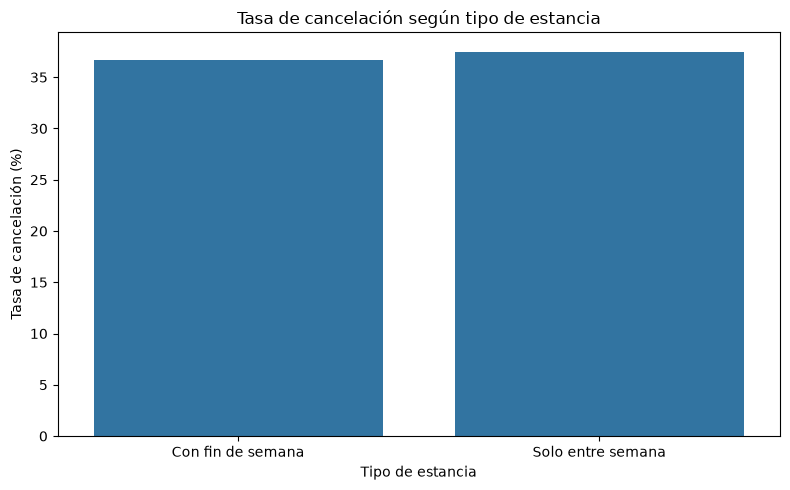

In [79]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=weekend_analysis,
    x="tipo_estancia",
    y="tasa_cancelacion"
)

plt.title("Tasa de cancelación según tipo de estancia")
plt.xlabel("Tipo de estancia")
plt.ylabel("Tasa de cancelación (%)")

plt.tight_layout()
plt.show()

Tampoco se aprecian diferencias aquí.

## Características de la estancia
- Las reservas con mayor duración tienen una mayor probabilidad de cancelación.
- Las reservas realizadas para grupos o familias presentan un comportamiento de cancelación diferente al de las reservas individuales.
- Las reservas que incluyen solicitudes especiales presentan una menor probabilidad de cancelación, debido a que son clientes más comprometidos con la estancia.